In [1]:
import matplotlib.pyplot as plt
import numpy as np
import copy
import EXOSIMS.MissionSim
from astropy.time import Time
from tools.plotKeepoutMap import plotKeepoutMap
import os
if not "DISPLAY" in os.environ.keys():  # Check environment for keys
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
else:
    import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib import colors
import argparse
import json
from EXOSIMS.util.read_ipcluster_ensemble import gen_summary
from EXOSIMS.util.read_ipcluster_ensemble import read_all
from numpy import linspace
from matplotlib.ticker import NullFormatter, MaxNLocator
from matplotlib import ticker
import astropy.units as u
import matplotlib.patheffects as PathEffects
import datetime
import re

In [2]:
# L2 Halo Orbit
specL2 = {
  "seed": 183074220,
  "koAngles_SolarPanel":[56.0,124.0],
  "missionLife": 3,
  "checkKeepoutEnd": True,
  "pupilDiam": 2.37,
  "scienceInstruments": [
    { "name": "imager"
    }
  ],
  "starlightSuppressionSystems": [
    { "name": "HLC-565",
      "koAngles_Sun":[45.0,180.0],
      "koAngles_Earth":[45.0,180.0],
      "koAngles_Moon":[45.0,180.0],
      "koAngles_Small":[1.0,180.0]
    }
  ],
  "observingModes": [
    { "instName": "imager",
      "systName": "HLC-565",
      "detectionMode": True,
      "SNR": 5
    }
  ],
    "modules": {
        "PlanetPopulation": "SAG13",
        "StarCatalog": "EXOCAT1",
        "OpticalSystem": " ",
        "ZodiacalLight": " ",
        "BackgroundSources": " ",
        "PlanetPhysicalModel": " ",
        "Observatory": "ObservatoryL2Halo",
        "TimeKeeping": " ",
        "PostProcessing": " ",
        "Completeness": "BrownCompleteness",
        "TargetList": " ",
        "SimulatedUniverse": "SAG13Universe",
        "SurveySimulation": " ",
        "SurveyEnsemble": " ",
    }
}

# initialize mission sim
simL2 = EXOSIMS.MissionSim.MissionSim(**copy.deepcopy(specL2))
OSL2 = simL2.OpticalSystem
obsL2, TLL2, TKL2 = simL2.Observatory, simL2.TargetList, simL2.TimeKeeping

# time array
koEvaltimesL2 = Time(
    np.arange(TKL2.missionStart.value,
              TKL2.missionStart.value+TKL2.missionLife.to('day').value,
              1),
    format='mjd'
)

# construct koangles
systNamesL2 = np.unique([OSL2.observingModes[x]['syst']['name']
                       for x in np.arange(len(OSL2.observingModes))])
koStrL2     = ["koAngles_Sun", "koAngles_Moon", "koAngles_Earth", "koAngles_Small"]
koanglesL2  = np.zeros([len(systNamesL2),4,2])
for x in np.argsort(systNamesL2):
    rel_modeL2 = list(filter(lambda mode: mode['syst']['name'] == systNamesL2[x], OSL2.observingModes))[0]
    koanglesL2[x] = np.asarray([rel_modeL2['syst'][k] for k in koStrL2])

# storage arrays
NstarsL2 = min(30, len(TLL2.Name))  # ensures you don't exceed total number of stars
selected_indicesL2 = np.arange(NstarsL2)
NtimesL2 = len(koEvaltimesL2)
kogoodL2  = np.zeros((NstarsL2, NtimesL2), dtype=bool)
culpritL2 = np.zeros((NstarsL2, NtimesL2, 12), dtype=bool)

# loop over all stars
for idx, i in enumerate(selected_indicesL2):
    for t, date in enumerate(koEvaltimesL2):
        tmpkogoodL2, r_bodyL2, r_targL2, tmpculpritL2, koangleArrayL2 = obsL2.keepout(
            TLL2, [i, i], date, koanglesL2, True
        )
        kogoodL2[idx, t]   = tmpkogoodL2[0,0,0]
        culpritL2[idx, t,:] = tmpculpritL2[0,0,0,:]

Imported SurveySimulation (prototype) from EXOSIMS.Prototypes.SurveySimulation
Numpy random seed is: 183074220
Imported SAG13Universe (implementation) from EXOSIMS.SimulatedUniverse.SAG13Universe
Imported TargetList (prototype) from EXOSIMS.Prototypes.TargetList
Imported EXOCAT1 (implementation) from EXOSIMS.StarCatalog.EXOCAT1
Imported OpticalSystem (prototype) from EXOSIMS.Prototypes.OpticalSystem
Imported ZodiacalLight (prototype) from EXOSIMS.Prototypes.ZodiacalLight
Imported PostProcessing (prototype) from EXOSIMS.Prototypes.PostProcessing
Imported BackgroundSources (prototype) from EXOSIMS.Prototypes.BackgroundSources
Imported BrownCompleteness (implementation) from EXOSIMS.Completeness.BrownCompleteness
Imported SAG13 (implementation) from EXOSIMS.PlanetPopulation.SAG13
Imported PlanetPhysicalModel (prototype) from EXOSIMS.Prototypes.PlanetPhysicalModel
Loading cached completeness file from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelBrownCompleteness10000000

/Users/Yael/Desktop/EXOSIMS/EXOSIMS/MissionSim.py:275: UserWarning: 
The following init keywords were not found in any outspec:
	       haloStartTime (ObservatoryL2Halo)

  warnings.warn(warnstr)


Loading cached dynamic completeness array from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelEXOCAT113aa09371b58223d301ce046c6aeb69a.dcomp".
Dynamic completeness array loaded from cache.
Imported ObservatoryL2Halo (implementation) from EXOSIMS.Observatory.ObservatoryL2Halo
    orbitdatapath is none
    orbitdatapath (/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/L2_halo_orbit_six_month.p) exists
Imported TimeKeeping (prototype) from EXOSIMS.Prototypes.TimeKeeping
OBendTimes is: [1095.75] d
Loading cached keepout map file from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/koMap_b69908b0a00f36e1a3b3ccf9e94761bf.komap
Keepout Map loaded from cache.
HLC-565
Loading cached fZ from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.starkfZ
Loading cached fZmins from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729

Starlight Suppression System: 100%|██████████| 1/1 [00:00<00:00, 113.45it/s]


In [3]:
# TESS Orbit
specTESS = {
  "seed": 183074220,
  "koAngles_SolarPanel":[56.0,124.0],
  "missionLife": 3,
  "checkKeepoutEnd": True,
  "pupilDiam": 2.37,
  "scienceInstruments": [
    { "name": "imager"
    }
  ],
  "starlightSuppressionSystems": [
    { "name": "HLC-565",
      "koAngles_Sun":[45.0,180.0],
      "koAngles_Earth":[45.0,180.0],
      "koAngles_Moon":[45.0,180.0],
      "koAngles_Small":[1.0,180.0]
    }
  ],
  "observingModes": [
    { "instName": "imager",
      "systName": "HLC-565",
      "detectionMode": True,
      "SNR": 5
    }
  ],
    "modules": {
        "PlanetPopulation": "SAG13",
        "StarCatalog": "EXOCAT1",
        "OpticalSystem": " ",
        "ZodiacalLight": " ",
        "BackgroundSources": " ",
        "PlanetPhysicalModel": " ",
        "Observatory": "ObservatoryTESScsv",
        "TimeKeeping": " ",
        "PostProcessing": " ",
        "Completeness": "BrownCompleteness",
        "TargetList": " ",
        "SimulatedUniverse": "SAG13Universe",
        "SurveySimulation": " ",
        "SurveyEnsemble": " ",
    }
}

# initialize mission sim
simTESS = EXOSIMS.MissionSim.MissionSim(**copy.deepcopy(specTESS))
OSTESS = simTESS.OpticalSystem
obsTESS, TLTESS, TKTESS = simTESS.Observatory, simTESS.TargetList, simTESS.TimeKeeping

# time array
koEvaltimesTESS = Time(
    np.arange(TKTESS.missionStart.value,
              TKTESS.missionStart.value+TKTESS.missionLife.to('day').value,
              1),
    format='mjd'
)

# construct koangles
systNamesTESS = np.unique([OSTESS.observingModes[x]['syst']['name']
                       for x in np.arange(len(OSTESS.observingModes))])
koStrTESS     = ["koAngles_Sun", "koAngles_Moon", "koAngles_Earth", "koAngles_Small"]
koanglesTESS  = np.zeros([len(systNamesTESS),4,2])
for x in np.argsort(systNamesTESS):
    rel_modeTESS = list(filter(lambda mode: mode['syst']['name'] == systNamesTESS[x], OSTESS.observingModes))[0]
    koanglesTESS[x] = np.asarray([rel_modeTESS['syst'][k] for k in koStrTESS])

# storage arrays
NstarsTESS = min(30, len(TLTESS.Name))  # ensures you don't exceed total number of stars
selected_indicesTESS = np.arange(NstarsTESS)
NtimesTESS = len(koEvaltimesTESS)
kogoodTESS  = np.zeros((NstarsTESS, NtimesTESS), dtype=bool)
culpritTESS = np.zeros((NstarsTESS, NtimesTESS, 12), dtype=bool)

# loop over all stars
for idx, i in enumerate(selected_indicesTESS):
    for t, date in enumerate(koEvaltimesTESS):
        tmpkogoodTESS, r_bodyTESS, r_targTESS, tmpculpritTESS, koangleArrayTESS = obsTESS.keepout(
            TLTESS, [i, i], date, koanglesTESS, True
        )
        kogoodTESS[idx, t]   = tmpkogoodTESS[0,0,0]
        culpritTESS[idx, t,:] = tmpculpritTESS[0,0,0,:]

Imported SurveySimulation (prototype) from EXOSIMS.Prototypes.SurveySimulation
Numpy random seed is: 183074220
Imported SAG13Universe (implementation) from EXOSIMS.SimulatedUniverse.SAG13Universe
Imported TargetList (prototype) from EXOSIMS.Prototypes.TargetList
Imported EXOCAT1 (implementation) from EXOSIMS.StarCatalog.EXOCAT1
Imported OpticalSystem (prototype) from EXOSIMS.Prototypes.OpticalSystem
Imported ZodiacalLight (prototype) from EXOSIMS.Prototypes.ZodiacalLight
Imported PostProcessing (prototype) from EXOSIMS.Prototypes.PostProcessing
Imported BackgroundSources (prototype) from EXOSIMS.Prototypes.BackgroundSources
Imported BrownCompleteness (implementation) from EXOSIMS.Completeness.BrownCompleteness
Imported SAG13 (implementation) from EXOSIMS.PlanetPopulation.SAG13
Imported PlanetPhysicalModel (prototype) from EXOSIMS.Prototypes.PlanetPhysicalModel
Loading cached completeness file from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelBrownCompleteness10000000

/Users/Yael/Desktop/EXOSIMS/EXOSIMS/MissionSim.py:275: UserWarning: 
The following init keywords were not found in any outspec:
	       tessStartTime (ObservatoryTESScsv)

  warnings.warn(warnstr)


Loading cached keepout map file from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/koMap_b69908b0a00f36e1a3b3ccf9e94761bf.komap
Keepout Map loaded from cache.
HLC-565
Loading cached fZ from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.starkfZ
Loading cached fZmins from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.fZmin
Imported SurveyEnsemble (prototype) from EXOSIMS.Prototypes.SurveyEnsemble

The following keywords are used in multiple inits (this is ok):
	Rprange
	arange
	cachedir
	esigma
	missionStart
	prange
	smaknee

146 keywords were set to their default values.


Starlight Suppression System: 100%|██████████| 1/1 [00:00<00:00, 111.72it/s]


In [9]:
# Kepler Earth-Trailing Orbit
specKep = {
  "seed": 183074220,
  "koAngles_SolarPanel":[56.0,124.0],
  "missionLife": 3,
  "checkKeepoutEnd": True,
  "pupilDiam": 2.37,
  "scienceInstruments": [
    { "name": "imager"
    }
  ],
  "starlightSuppressionSystems": [
    { "name": "HLC-565",
      "koAngles_Sun":[45.0,180.0],
      "koAngles_Earth":[45.0,180.0],
      "koAngles_Moon":[45.0,180.0],
      "koAngles_Small":[1.0,180.0]
    }
  ],
  "observingModes": [
    { "instName": "imager",
      "systName": "HLC-565",
      "detectionMode": True,
      "SNR": 5
    }
  ],
    "modules": {
        "PlanetPopulation": "SAG13",
        "StarCatalog": "EXOCAT1",
        "OpticalSystem": " ",
        "ZodiacalLight": " ",
        "BackgroundSources": " ",
        "PlanetPhysicalModel": " ",
        "Observatory": "ObservatoryKeplercsv",
        "TimeKeeping": " ",
        "PostProcessing": " ",
        "Completeness": "BrownCompleteness",
        "TargetList": " ",
        "SimulatedUniverse": "SAG13Universe",
        "SurveySimulation": " ",
        "SurveyEnsemble": " ",
    }
}

# initialize mission sim
simKep = EXOSIMS.MissionSim.MissionSim(**copy.deepcopy(specKep))
OSKep = simKep.OpticalSystem
obsKep, TLKep, TKKep = simKep.Observatory, simKep.TargetList, simKep.TimeKeeping

# time array
koEvaltimesKep = Time(
    np.arange(TKKep.missionStart.value,
              TKKep.missionStart.value+TKKep.missionLife.to('day').value,
              1),
    format='mjd'
)

# construct koangles
systNamesKep = np.unique([OSKep.observingModes[x]['syst']['name']
                       for x in np.arange(len(OSKep.observingModes))])
koStrKep     = ["koAngles_Sun", "koAngles_Moon", "koAngles_Earth", "koAngles_Small"]
koanglesKep  = np.zeros([len(systNamesKep),4,2])
for x in np.argsort(systNamesKep):
    rel_modeKep = list(filter(lambda mode: mode['syst']['name'] == systNamesKep[x], OSKep.observingModes))[0]
    koanglesKep[x] = np.asarray([rel_modeKep['syst'][k] for k in koStrKep])

# storage arrays
NstarsKep = min(30, len(TLKep.Name))  # ensures you don't exceed total number of stars
selected_indicesKep = np.arange(NstarsKep)
NtimesKep = len(koEvaltimesKep)
kogoodKep  = np.zeros((NstarsKep, NtimesKep), dtype=bool)
culpritKep = np.zeros((NstarsKep, NtimesKep, 12), dtype=bool)

# loop over all stars
for idx, i in enumerate(selected_indicesKep):
    for t, date in enumerate(koEvaltimesKep):
        tmpkogoodKep, r_bodyKep, r_targKep, tmpculpritKep, koangleArrayKep = obsKep.keepout(
            TLKep, [i, i], date, koanglesKep, True
        )
        kogoodKep[idx, t]   = tmpkogoodKep[0,0,0]
        culpritKep[idx, t,:] = tmpculpritKep[0,0,0,:]

Imported SurveySimulation (prototype) from EXOSIMS.Prototypes.SurveySimulation
Numpy random seed is: 183074220
Imported SAG13Universe (implementation) from EXOSIMS.SimulatedUniverse.SAG13Universe
Imported TargetList (prototype) from EXOSIMS.Prototypes.TargetList
Imported EXOCAT1 (implementation) from EXOSIMS.StarCatalog.EXOCAT1
Imported OpticalSystem (prototype) from EXOSIMS.Prototypes.OpticalSystem
Imported ZodiacalLight (prototype) from EXOSIMS.Prototypes.ZodiacalLight
Imported PostProcessing (prototype) from EXOSIMS.Prototypes.PostProcessing
Imported BackgroundSources (prototype) from EXOSIMS.Prototypes.BackgroundSources
Imported BrownCompleteness (implementation) from EXOSIMS.Completeness.BrownCompleteness
Imported SAG13 (implementation) from EXOSIMS.PlanetPopulation.SAG13
Imported PlanetPhysicalModel (prototype) from EXOSIMS.Prototypes.PlanetPhysicalModel
Loading cached completeness file from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelBrownCompleteness10000000

/Users/Yael/Desktop/EXOSIMS/EXOSIMS/MissionSim.py:275: UserWarning: 
The following init keywords were not found in any outspec:
	     keplerStartTime (ObservatoryKeplercsv)

  warnings.warn(warnstr)


Loading cached dynamic completeness array from "/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/SAG13PlanetPhysicalModelEXOCAT113aa09371b58223d301ce046c6aeb69a.dcomp".
Dynamic completeness array loaded from cache.
Imported ObservatoryKeplercsv (implementation) from EXOSIMS.Observatory.ObservatoryKeplercsv
orbitdatapath is none
    orbitdatapath (/Users/Yael/.EXOSIMS/cache/v3.7.0alpha/keplerAdjcsv.p) exists
Imported TimeKeeping (prototype) from EXOSIMS.Prototypes.TimeKeeping
OBendTimes is: [1095.75] d
Loading cached keepout map file from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/koMap_b69908b0a00f36e1a3b3ccf9e94761bf.komap
Keepout Map loaded from cache.
HLC-565
Loading cached fZ from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.starkfZ
Loading cached fZmins from /Users/Yael/.EXOSIMS/cache/v3.7.0alpha/BrownCompletenessTargetListOpticalSysteme0f78bfe1e9605be875077ac09febb65_60_HLC-565_60634.0_61729.75.fZmin

Starlight Suppression System: 100%|██████████| 1/1 [00:00<00:00, 120.34it/s]


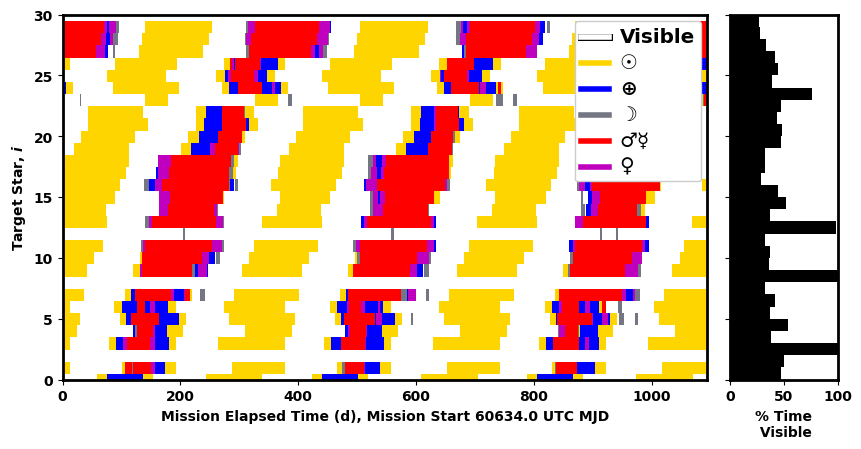

<Figure size 640x480 with 0 Axes>

In [4]:
# L2 Halo Keepout Map Colors
cmap = colors.ListedColormap(
   ["white", "#FFD500", "blue", "#747783", "red", "m", "red"]
)  # colors for used to indicate a culprit behind keepout
bounds = [0, 1, 2, 3, 4, 5, 6, 7]
norm = colors.BoundaryNorm(bounds, cmap.N)

# creating an array of colors based on culprit
koColor = np.zeros([TLL2.nStars, len(koEvaltimesL2)])
koColor = (
    culpritL2[:, :, 0] * 1
    + culpritL2[:, :, 2] * 2
    + culpritL2[:, :, 1] * 3
    + culpritL2[:, :, 3] * 6
    + culpritL2[:, :, 4] * 5
    + culpritL2[:, :, 5] * 4
    + culpritL2[:, :, 11] * 1
)
koColor.astype("int")


# plotting colors on a 2d map
plt.close(546832183)
fig = plt.figure(546832183, figsize=(10, 5))
fig.subplots_adjust(bottom=0.15)
gs = gridspec.GridSpec(1, 2, width_ratios=[6, 1], height_ratios=[1])
gs.update(wspace=0.06, hspace=0.06)  # set the spacing between axes.
plt.rc("axes", linewidth=2)
plt.rc("lines", linewidth=2)
plt.rcParams["axes.linewidth"] = 2
plt.rc("font", weight="bold")
ax2 = plt.subplot(gs[1])
ax = plt.subplot(gs[0])


if (
    koColor.shape[0] > 100
):  # Determine maximum number of stars to track keepouts for
    NUMBER_Y = 100
else:
    NUMBER_Y = koColor.shape[0]
sIndsL2 = np.linspace(
    0, koColor.shape[0], num=NUMBER_Y, endpoint=False, dtype=int
).tolist()
img = plt.imshow(
    koColor[sIndsL2, 0 : int(np.floor(len(koEvaltimesL2)))],
    aspect="auto",  # 4,
    cmap=cmap,
    interpolation="none",
    origin="lower",
    norm=norm,
)


ax.set_xlabel(
    "Mission Elapsed Time (d), Mission Start %s UTC MJD"
    % (str(TKL2.missionStart.value)),
    weight="bold",
)
ax.set_ylabel(r"Target Star, $i$", weight="bold")
ax.set_xlim(left=0.0, right=np.max(koEvaltimesL2).value - TKL2.missionStart.value)
ax.set_ylim(bottom=0.0, top=NUMBER_Y)

outline = PathEffects.withStroke(linewidth=5, foreground="black")
plt.plot(
    [-1.0, -1.0],
    [-1.0, -1.0],
    color=cmap.colors[0],
    label="Visible",
    path_effects=[outline],
    )
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[1], label="\u2609")
plt.plot(
    [-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[2], label=r"$\oplus$"
)  ##\u2641$')
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[3], label="\u263D")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[4], label="\u2642\u263F")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[5], label="\u2640")
# plt.plot([-1.,-1.],[-1.,-1.],color=cmap.colors[6],label=ur'$\u263F$')  duplicate color so appended above
leg = plt.legend(framealpha=1.0)
# get the lines and texts inside legend box
leg_lines = leg.get_lines()
leg_texts = leg.get_texts()
# bulk-set the properties of all lines and texts
plt.setp(leg_lines, linewidth=4)
plt.setp(leg_texts, fontsize="x-large")
nullfmt = NullFormatter()
ax2.yaxis.set_major_formatter(nullfmt)

# Plot horizontal histogram
tTotal = (
    np.max(koEvaltimesL2).value - TKL2.missionStart.value
)  # Calculate total time width of koMap
tVisL2 = list()  # stores time visible of each star
for i in np.arange(
    len(sIndsL2)
):  # iterate over all stars and append amount of time each star is visible
    tVisL2.append(len(np.where(koColor[sIndsL2[i], :] == 0)[0]))

widthL2 = np.zeros(len(tVisL2)) + 1.0
ax2.barh(
    np.arange(len(sIndsL2)) + 0.5,
    np.asarray(tVisL2, dtype=float) / tTotal * 100.0,
    widthL2,
    align="center",
    color="black",
)
ax2.set_xlim(left=0.0, right=100.0)
ax2.set_ylim(bottom=0.0, top=NUMBER_Y)
ax2.set_xlabel("% Time\n Visible", weight="bold")
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

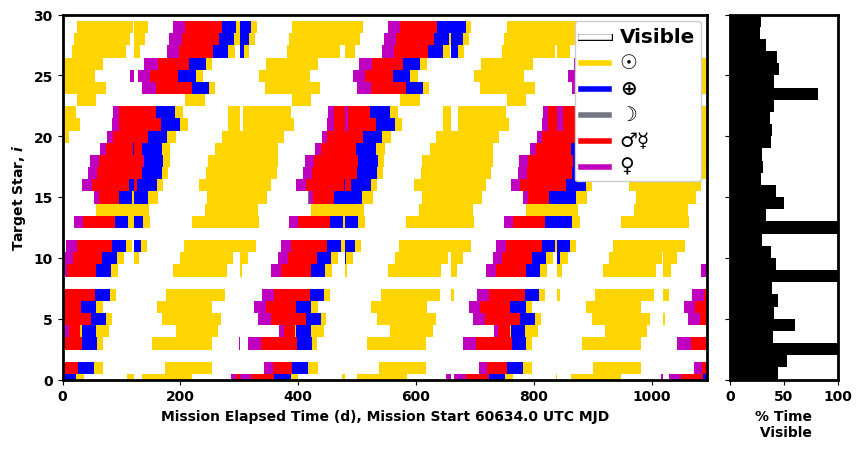

<Figure size 640x480 with 0 Axes>

In [5]:
# TESS Orbit Keepout Map Colors
cmap = colors.ListedColormap(
   ["white", "#FFD500", "blue", "#747783", "red", "m", "red"]
)  # colors for used to indicate a culprit behind keepout
bounds = [0, 1, 2, 3, 4, 5, 6, 7]
norm = colors.BoundaryNorm(bounds, cmap.N)

# creating an array of colors based on culprit
koColor = np.zeros([TLTESS.nStars, len(koEvaltimesTESS)])
koColor = (
    culpritTESS[:, :, 0] * 1
    + culpritTESS[:, :, 2] * 2
    + culpritTESS[:, :, 1] * 3
    + culpritTESS[:, :, 3] * 6
    + culpritTESS[:, :, 4] * 5
    + culpritTESS[:, :, 5] * 4
    + culpritTESS[:, :, 11] * 1
)
koColor.astype("int")


# plotting colors on a 2d map
plt.close(546832183)
fig = plt.figure(546832183, figsize=(10, 5))
fig.subplots_adjust(bottom=0.15)
gs = gridspec.GridSpec(1, 2, width_ratios=[6, 1], height_ratios=[1])
gs.update(wspace=0.06, hspace=0.06)  # set the spacing between axes.
plt.rc("axes", linewidth=2)
plt.rc("lines", linewidth=2)
plt.rcParams["axes.linewidth"] = 2
plt.rc("font", weight="bold")
ax2 = plt.subplot(gs[1])
ax = plt.subplot(gs[0])


if (
    koColor.shape[0] > 100
):  # Determine maximum number of stars to track keepouts for
    NUMBER_Y = 100
else:
    NUMBER_Y = koColor.shape[0]
sIndsTESS = np.linspace(
    0, koColor.shape[0], num=NUMBER_Y, endpoint=False, dtype=int
).tolist()
img = plt.imshow(
    koColor[sIndsTESS, 0 : int(np.floor(len(koEvaltimesTESS)))],
    aspect="auto",  # 4,
    cmap=cmap,
    interpolation="none",
    origin="lower",
    norm=norm,
)


ax.set_xlabel(
    "Mission Elapsed Time (d), Mission Start %s UTC MJD"
    % (str(TKTESS.missionStart.value)),
    weight="bold",
)
ax.set_ylabel(r"Target Star, $i$", weight="bold")
ax.set_xlim(left=0.0, right=np.max(koEvaltimesTESS).value - TKTESS.missionStart.value)
ax.set_ylim(bottom=0.0, top=NUMBER_Y)

outline = PathEffects.withStroke(linewidth=5, foreground="black")
plt.plot(
    [-1.0, -1.0],
    [-1.0, -1.0],
    color=cmap.colors[0],
    label="Visible",
    path_effects=[outline],
    )
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[1], label="\u2609")
plt.plot(
    [-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[2], label=r"$\oplus$"
)  ##\u2641$')
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[3], label="\u263D")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[4], label="\u2642\u263F")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[5], label="\u2640")
# plt.plot([-1.,-1.],[-1.,-1.],color=cmap.colors[6],label=ur'$\u263F$')  duplicate color so appended above
leg = plt.legend(framealpha=1.0)
# get the lines and texts inside legend box
leg_lines = leg.get_lines()
leg_texts = leg.get_texts()
# bulk-set the properties of all lines and texts
plt.setp(leg_lines, linewidth=4)
plt.setp(leg_texts, fontsize="x-large")
nullfmt = NullFormatter()
ax2.yaxis.set_major_formatter(nullfmt)

# Plot horizontal histogram
tTotal = (
    np.max(koEvaltimesTESS).value - TKTESS.missionStart.value
)  # Calculate total time width of koMap
tVisTESS = list()  # stores time visible of each star
for i in np.arange(
    len(sIndsTESS)
):  # iterate over all stars and append amount of time each star is visible
    tVisTESS.append(len(np.where(koColor[sIndsTESS[i], :] == 0)[0]))

widthTESS = np.zeros(len(tVisTESS)) + 1.0
ax2.barh(
    np.arange(len(sIndsTESS)) + 0.5,
    np.asarray(tVisTESS, dtype=float) / tTotal * 100.0,
    widthTESS,
    align="center",
    color="black",
)
ax2.set_xlim(left=0.0, right=100.0)
ax2.set_ylim(bottom=0.0, top=NUMBER_Y)
ax2.set_xlabel("% Time\n Visible", weight="bold")
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

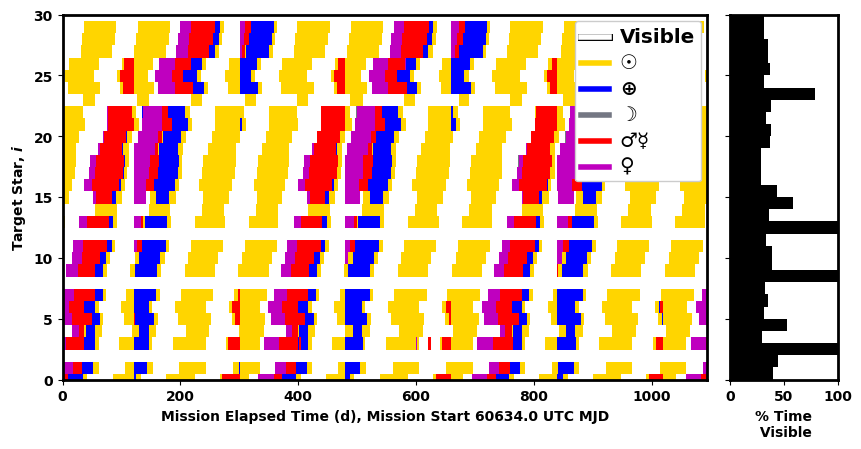

<Figure size 640x480 with 0 Axes>

In [10]:
# Kepler Halo Keepout Map Colors
cmap = colors.ListedColormap(
   ["white", "#FFD500", "blue", "#747783", "red", "m", "red"]
)  # colors for used to indicate a culprit behind keepout
bounds = [0, 1, 2, 3, 4, 5, 6, 7]
norm = colors.BoundaryNorm(bounds, cmap.N)

# creating an array of colors based on culprit
koColor = np.zeros([TLKep.nStars, len(koEvaltimesKep)])
koColor = (
    culpritKep[:, :, 0] * 1
    + culpritKep[:, :, 2] * 2
    + culpritKep[:, :, 1] * 3
    + culpritKep[:, :, 3] * 6
    + culpritKep[:, :, 4] * 5
    + culpritKep[:, :, 5] * 4
    + culpritKep[:, :, 11] * 1
)
koColor.astype("int")


# plotting colors on a 2d map
plt.close(546832183)
fig = plt.figure(546832183, figsize=(10, 5))
fig.subplots_adjust(bottom=0.15)
gs = gridspec.GridSpec(1, 2, width_ratios=[6, 1], height_ratios=[1])
gs.update(wspace=0.06, hspace=0.06)  # set the spacing between axes.
plt.rc("axes", linewidth=2)
plt.rc("lines", linewidth=2)
plt.rcParams["axes.linewidth"] = 2
plt.rc("font", weight="bold")
ax2 = plt.subplot(gs[1])
ax = plt.subplot(gs[0])


if (
    koColor.shape[0] > 100
):  # Determine maximum number of stars to track keepouts for
    NUMBER_Y = 100
else:
    NUMBER_Y = koColor.shape[0]
sIndsKep = np.linspace(
    0, koColor.shape[0], num=NUMBER_Y, endpoint=False, dtype=int
).tolist()
img = plt.imshow(
    koColor[sIndsKep, 0 : int(np.floor(len(koEvaltimesKep)))],
    aspect="auto",  # 4,
    cmap=cmap,
    interpolation="none",
    origin="lower",
    norm=norm,
)


ax.set_xlabel(
    "Mission Elapsed Time (d), Mission Start %s UTC MJD"
    % (str(TKKep.missionStart.value)),
    weight="bold",
)
ax.set_ylabel(r"Target Star, $i$", weight="bold")
ax.set_xlim(left=0.0, right=np.max(koEvaltimesKep).value - TKKep.missionStart.value)
ax.set_ylim(bottom=0.0, top=NUMBER_Y)

outline = PathEffects.withStroke(linewidth=5, foreground="black")
plt.plot(
    [-1.0, -1.0],
    [-1.0, -1.0],
    color=cmap.colors[0],
    label="Visible",
    path_effects=[outline],
    )
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[1], label="\u2609")
plt.plot(
    [-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[2], label=r"$\oplus$"
)  ##\u2641$')
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[3], label="\u263D")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[4], label="\u2642\u263F")
plt.plot([-1.0, -1.0], [-1.0, -1.0], color=cmap.colors[5], label="\u2640")
# plt.plot([-1.,-1.],[-1.,-1.],color=cmap.colors[6],label=ur'$\u263F$')  duplicate color so appended above
leg = plt.legend(framealpha=1.0)
# get the lines and texts inside legend box
leg_lines = leg.get_lines()
leg_texts = leg.get_texts()
# bulk-set the properties of all lines and texts
plt.setp(leg_lines, linewidth=4)
plt.setp(leg_texts, fontsize="x-large")
nullfmt = NullFormatter()
ax2.yaxis.set_major_formatter(nullfmt)

# Plot horizontal histogram
tTotal = (
    np.max(koEvaltimesKep).value - TKKep.missionStart.value
)  # Calculate total time width of koMap
tVisKep = list()  # stores time visible of each star
for i in np.arange(
    len(sIndsKep)
):  # iterate over all stars and append amount of time each star is visible
    tVisKep.append(len(np.where(koColor[sIndsKep[i], :] == 0)[0]))

widthKep = np.zeros(len(tVisKep)) + 1.0
ax2.barh(
    np.arange(len(sIndsKep)) + 0.5,
    np.asarray(tVisKep, dtype=float) / tTotal * 100.0,
    widthKep,
    align="center",
    color="black",
)
ax2.set_xlim(left=0.0, right=100.0)
ax2.set_ylim(bottom=0.0, top=NUMBER_Y)
ax2.set_xlabel("% Time\n Visible", weight="bold")
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

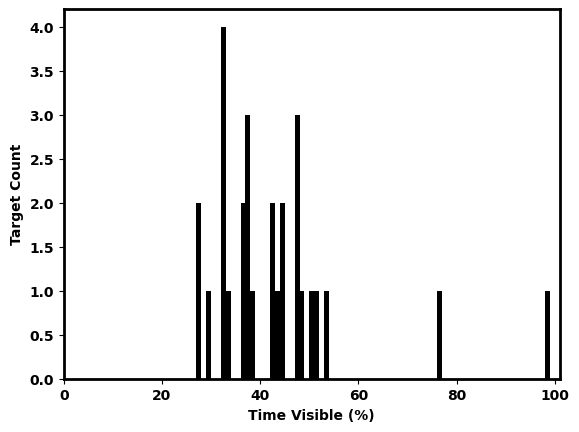

<Figure size 640x480 with 0 Axes>

In [6]:
# L2 Histogram Percent Time Visible
plt.close(98735654)
fig = plt.figure(98735654)
binsL2 = np.linspace(
    start=0,
    stop=np.round(np.max(tVisL2) / tTotal * 100.0),
    num=int(np.round(np.max(tVisL2) / tTotal * 100.0) + 1),
)
plt.hist(
    np.asarray(tVisL2) / tTotal * 100.0,
    bins=binsL2,
    color="black",
    alpha=1.0,
    histtype="bar",
    ec="black",
)
plt.ylabel("Target Count", weight="bold")
plt.xlabel("Time Visible (%)", weight="bold")
plt.xlim((0, np.ceil(np.max(tVisL2) / tTotal * 100.0)))
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

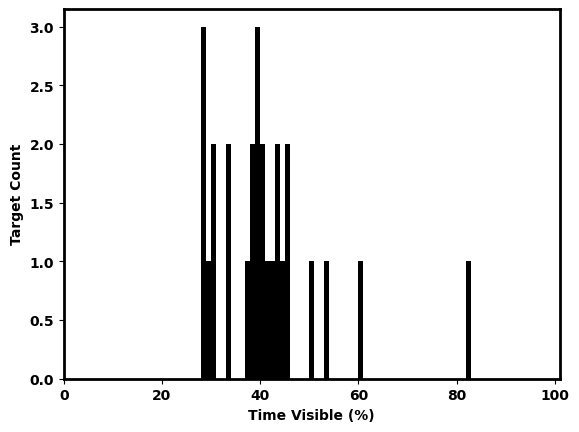

<Figure size 640x480 with 0 Axes>

In [7]:
# TESS Histogram Percent Time Visible
plt.close(98735654)
fig = plt.figure(98735654)
binsTESS = np.linspace(
    start=0,
    stop=np.round(np.max(tVisTESS) / tTotal * 100.0),
    num=int(np.round(np.max(tVisTESS) / tTotal * 100.0) + 1),
)
plt.hist(
    np.asarray(tVisTESS) / tTotal * 100.0,
    bins=binsTESS,
    color="black",
    alpha=1.0,
    histtype="bar",
    ec="black",
)
plt.ylabel("Target Count", weight="bold")
plt.xlabel("Time Visible (%)", weight="bold")
plt.xlim((0, np.ceil(np.max(tVisTESS) / tTotal * 100.0)))
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

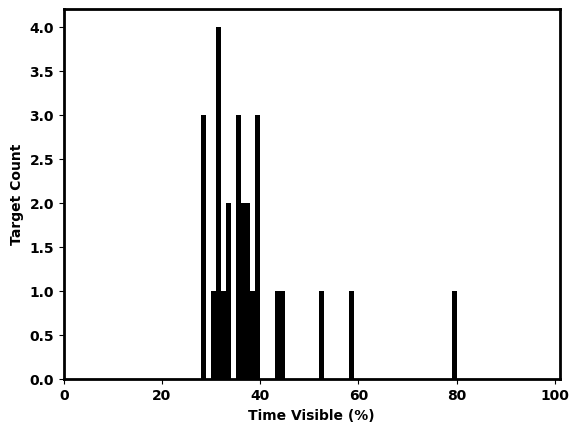

<Figure size 640x480 with 0 Axes>

In [11]:
# Kepler Histogram Percent Time Visible
plt.close(98735654)
fig = plt.figure(98735654)
binsKep = np.linspace(
    start=0,
    stop=np.round(np.max(tVisKep) / tTotal * 100.0),
    num=int(np.round(np.max(tVisKep) / tTotal * 100.0) + 1),
)
plt.hist(
    np.asarray(tVisKep) / tTotal * 100.0,
    bins=binsKep,
    color="black",
    alpha=1.0,
    histtype="bar",
    ec="black",
)
plt.ylabel("Target Count", weight="bold")
plt.xlabel("Time Visible (%)", weight="bold")
plt.xlim((0, np.ceil(np.max(tVisKep) / tTotal * 100.0)))
#plt.show(block=False)
plt.show()
plt.gcf().canvas.draw()

DT = datetime.datetime
date = str(DT.now())  # ,"utf-8")
date = "".join(
    c + "_" for c in re.split("-|:| ", date)[0:-1]
)  # Removes seconds from date

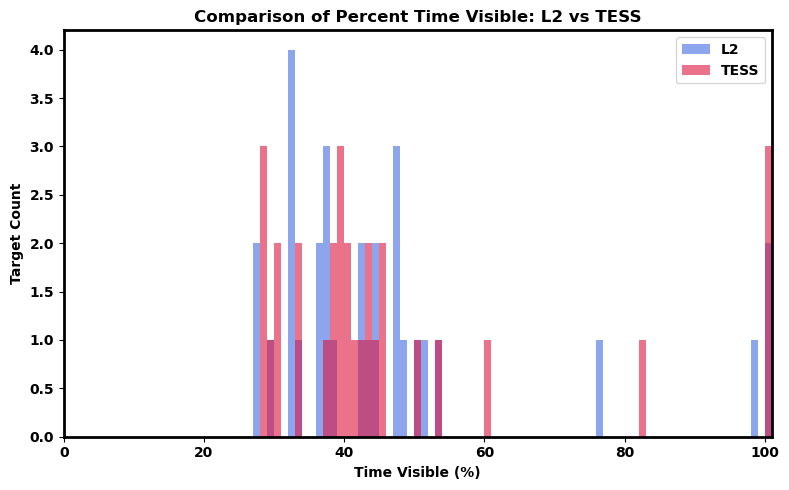

In [8]:
# --- Compute histogram bins consistently ---
# Use the same bin edges for both datasets for fair comparison
max_percent = np.ceil(
    max(np.max(tVisL2), np.max(tVisTESS)) / tTotal * 100.0
)
bins = np.linspace(0, max_percent, int(max_percent) + 1)

# --- Create combined histogram plot ---
plt.close(98735654)
fig = plt.figure(98735654, figsize=(8, 5))

# Plot both histograms with transparency
plt.hist(
    np.asarray(tVisL2) / tTotal * 100.0,
    bins=bins,
    color="royalblue",
    alpha=0.6,
    histtype="bar",
    ec="black",
    label="L2"
)
plt.hist(
    np.asarray(tVisTESS) / tTotal * 100.0,
    bins=bins,
    color="crimson",
    alpha=0.6,
    histtype="bar",
    ec="black",
    label="TESS"
)

# --- Labeling and formatting ---
plt.ylabel("Target Count", weight="bold")
plt.xlabel("Time Visible (%)", weight="bold")
plt.xlim((0, max_percent))
plt.legend(fontsize=10, frameon=True)
plt.title("Comparison of Percent Time Visible: L2 vs TESS", weight="bold")

plt.tight_layout()
plt.show()

# --- Timestamp (optional) ---
DT = datetime.datetime
date = str(DT.now())
date = "".join(c + "_" for c in re.split("-|:| ", date)[0:-1])

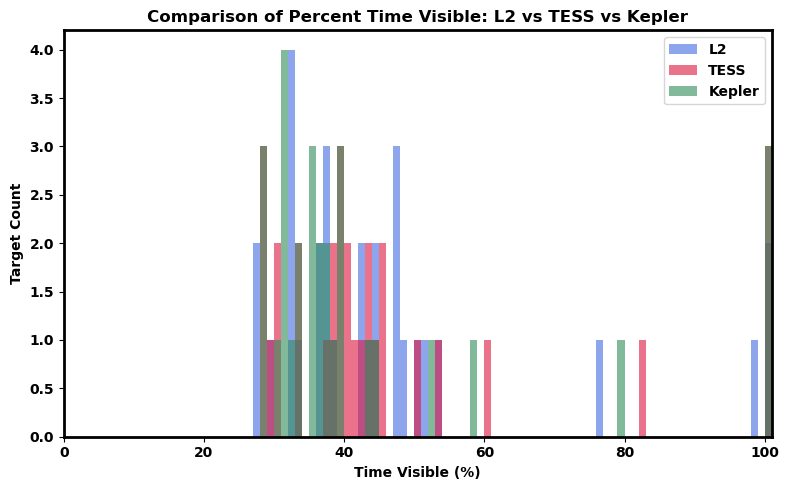

In [ ]:
# Stacked histogram: all three orbit types
max_percent = np.ceil(
    max(np.max(tVisL2), np.max(tVisTESS), np.max(tVisKep)) / tTotal * 100.0
)
bins = np.linspace(0, max_percent, int(max_percent) + 1)

plt.close(98735654)
fig = plt.figure(98735654, figsize=(8, 5))

# Plot each dataset with transparency and color
plt.hist(
    np.asarray(tVisL2)/tTotal * 100,
    bins=bins,
    color="royalblue",
    alpha=0.6,
    histtype="bar",
    ec="black",
    label="L2"
)
plt.hist(
    np.asarray(tVisTESS)/tTotal * 100,
    bins=bins,
    color="crimson",
    alpha=0.6,
    histtype="bar",
    ec="black",
    label="TESS"
)
plt.hist(
    np.asarray(tVisKep)/tTotal * 100,
    bins=bins,
    color="seagreen",
    alpha=0.6,
    histtype="bar",
    ec="black",
    label="Kepler"
)

plt.ylabel("Target Count", weight="bold")
plt.xlabel("Time Visible (%)", weight="bold")
plt.xlim((0, max_percent))
plt.legend(fontsize=10, frameon=True)
plt.title("Comparison of Percent Time Visible: L2 vs TESS vs Kepler", weight="bold")

plt.tight_layout()
plt.show()